# Classificação e Detecção de Smishing usando Machine Learning
----

- ### Aplicação prática de Inteligência Artificial para detecção de fraudes em mensagens de SMS.

- ### Pipeline de NLP utilizando [TensorFlow](https://www.tensorflow.org/), [KerasHub](https://keras.io/keras_hub/presets/) e [scikit-learn](https://scikit-learn.org/stable/#)

- ### **DistilBERT Multilingue com Transfer Learning & Fine-Tuning**

Este projeto é parte da Residência em Inteligência Artificial Avançada do [Instituto de Pesquisas ELDORADO (Brazil)](https://www.eldorado.org.br/).
Neste projeto, o objetivo é desenvolver um algoritmo de Inteligência Artificial para detecção e classificação de fraudes em mensagens SMS usando metodos de Aprendizado de Máquinas Supervisionado.

##### **© 2026**, Ana Maranho;  Ana C. Laet;  Camila Santana;  KALOMBOLA, C. M; Sophia De Godoy


- O conteúdo deste projeto é licenciado sob uma <a href="https://creativecommons.org/licenses/by/4.0/deed.fr" target='_blank'>Creative Commons Attribution 4.0 (CC BY 4.0)</a>,<br/>e os códigos estão em <a href="https://www.apache.org/licenses/LICENSE-2.0" target='_blank'>licence Apache 2.0</a>.

------

## Instalação e Importação de Bibliotecas

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="keras")

In [ ]:
# Instalação das bibliotecas para o fluxo TensorFlow e Keras Hub
!pip install -U tensorflow-text keras_hub keras

In [ ]:
import os
import shutil
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sb

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import(
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    accuracy_score,
    precision_recall_curve
)

import tensorflow as tf
import tensorflow_text as text

import keras
import keras_hub

%matplotlib inline
import IPython
import sys

tf.get_logger().setLevel('ERROR')

print("Bibliotecas configuradas.")

Bibliotecas configuradas.


### Verificação da instalação

In [ ]:
# Verificação das versões das bibliotecas Python importadas
print("Versão do Python: ",sys.version)
print("Versão do IPython: ",IPython.__version__)
print("Versão do NumPy: ",np.__version__)
print("Versão do Pandas: ",pd.__version__)
print("Versão do Matplotlib: ",matplotlib.__version__)
print("Versão do Seaborn: ",sb.__version__)
print("Versão do Sciki-Learn: ",sklearn.__version__)
print("Versão do TensorFlow: ",tf.__version__)
print("Versão do Keras:",keras.__version__)
print("Versão do Keras-hub: ",keras.__version__)
print("Versão do TensorFlow-Text: ",text.__version__)


Versão do Python:  3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Versão do IPython:  7.34.0
Versão do NumPy:  2.1.3
Versão do Pandas:  2.2.3
Versão do Matplotlib:  3.10.0
Versão do Seaborn:  0.13.2
Versão do Sciki-Learn:  1.6.1
Versão do TensorFlow:  2.21.0
Versão do Keras: 3.15.1
Versão do Keras-hub:  3.15.1
Versão do TensorFlow-Text:  2.21.1


## Configurando um estado aleatório

In [ ]:
import os

# Definindo um germe aleatório
GERME_ALEATORIO = 42

# Defini um estado aleatório para Python
os.environ['PYTHONHASHSEED'] = str(GERME_ALEATORIO)

# Defini um estado aleatório para Python random
import random
random.seed(GERME_ALEATORIO)

# Determinar um estado aleatório para Python
os.environ['PYTHONHASHSEED'] = str(GERME_ALEATORIO)

# Determinar um estado aleatório para Python random
import random
random.seed(GERME_ALEATORIO)

# Determinar um estado aleatório para NumPy
import numpy as np
np.random.seed(GERME_ALEATORIO)
# Definindo um estado aleatório para Keras
from tensorflow import keras
keras.utils.set_random_seed(GERME_ALEATORIO)
# Definindo um estado aleatório para TensorFlow
import tensorflow as tf
tf.random.set_seed(GERME_ALEATORIO)

os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'

print("Germe aleatório fixo")

Germe aleatório fixo


## Carregamento e preparação da base de dados

In [ ]:
df = pd.read_csv("/content/scamsdataset_pt_clean.csv")

# Mapeamento binario
mapeamento = {'Legitimate': 0, 'Smishing': 1}
df['classe'] = df['classe'].map(mapeamento)
# Remove linhas onde 'classe' é NaN e converter para int
df.dropna(subset=['classe'], inplace=True)
df['classe'] = df['classe'].astype(int)

# Repartição estratificada: 0.70 treino e 0.30 temporário (validação e teste)
X_train, X_temp, y_train, y_temp = train_test_split(
    df['texto'], df['classe'], test_size=0.3, random_state=GERME_ALEATORIO, stratify=df['classe']
)
# Validação 0.15 e teste 0.15
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=GERME_ALEATORIO, stratify=y_temp
)

### Conversão para tensores - tf.data.Dataset

 - Ajuste dos pesos para corregir o desbalanceamento

  - Configuração dos pesos das classes

In [ ]:
# Calculo dos pesos para balanceamento das classes - compensação do desbalanceamento
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
pesos_dict = dict(enumerate(class_weights))
print(f"Pesos aplicados: {pesos_dict}")

# Feeds de lote de dados
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

treino_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).batch(BATCH_SIZE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE)
teste_ds =  tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE)

treino_ds = treino_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
teste_ds = teste_ds.cache().prefetch(buffer_size=AUTOTUNE)

Pesos aplicados: {0: np.float64(0.8463726884779517), 1: np.float64(1.2217659137577002)}


## Carregando modelo pré-treinado

- ### Transfer Learning & Fine-Tuning
- ### Definição da losses function, métricas e optimizer

In [ ]:
# Construção do modelo
def build_classifier_model(learning_rate=2e-5, unfreeze_last_n_layers=1):
  # Carregando a arquitetura, pesos, processador e classificador
  modelo = keras_hub.models.DistilBertTextClassifier.from_preset(
      "distil_bert_base_multi",
      num_classes=1,
      activation="sigmoid"
  )
  # Congelamento dos pesos da rede
  modelo.backbone.trainable = False

  if unfreeze_last_n_layers > 0:
    for layer in modelo.backbone.transformer_layers[-unfreeze_last_n_layers:]:
      layer.trainable = True
    print(f"--> Fine-Tuning aplicado para as ultimas {unfreeze_last_n_layers} camada(s) do DistilBERT.")
  else:
    print("--> Apenas a camada de classificação final será treinada (Feature Extraction).")

  # Compilação
  modelo.compile(
          optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
          loss=tf.keras.losses.BinaryCrossentropy(),
          # Métricas para avaliação em tempo real
          metrics=[
              'accuracy',
              tf.keras.metrics.Precision(name='precision'),
              tf.keras.metrics.Recall(name='recall')
          ]
      )

  return modelo
# Instancia descogelando a ultima camada
modelo= build_classifier_model(learning_rate=2e-5, unfreeze_last_n_layers=1)

--> Fine-Tuning aplicado para as ultimas 1 camada(s) do DistilBERT.


### Verificando se o modelo é executado com a saída do modelo de pré-processamento
- Prévia de fluxo de tensores
- Visualização da estrutura do modelo

In [ ]:
# Verifica se o modelo é executado com a saída do modelo de pré-processamento
print("--- Testando saída do modelo ---")
# Instanciando o pré-processador
preprocessor = keras_hub.models.DistilBertTextClassifierPreprocessor.from_preset(
    "distil_bert_base_multi"
)
preprocessed_text = preprocessor(tf.constant(["Este é um teste para verificar o fluxo de tensores."]))
# Passando o texto pré-processado para o modelo
bert_raw_result = modelo(preprocessed_text)
print(f"Probabilidade calculada (Tensor): {bert_raw_result.numpy()}\n")

--- Testando saída do modelo ---
Probabilidade calculada (Tensor): [[0.49209642]]



### Exibindo a estrutura do modelo

In [ ]:
print("Arquitetura completa:\n")
modelo.summary()

Arquitetura completa:



Preprocessor: "distil_bert_text_classifier_preprocessor_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ distil_bert_tokenizer (DistilBertTokenizer)                   │                      Vocab size: 119,547 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "distil_bert_text_classifier_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ distil_bert_backbone          │ (None, None, 768)         │     134,734,080 │ padding_mask[0][0],        │
│ (DistilBertBackbone)          │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 768)               │               0 │ distil_bert_backbone[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pooled_dense (Dense)          │ (None, 768)               │         590,592 │ get_item_1[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 768)               │               0 │ pooled_dense[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 1)                 │             769 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 135,325,441 (516.23 MB)

 Trainable params: 7,679,233 (29.29 MB)

 Non-trainable params: 127,646,208 (486.93 MB)

# Treinamento do modelo

In [ ]:
epochs = 4

print(f"Iniciando treinamento...\n")
history = modelo.fit(
    x=treino_ds,
    validation_data=val_ds,
    epochs=epochs,
    class_weight=pesos_dict
)

- ### Configuração do Limiar ótimo

In [ ]:
print("\n--- Calculando o limiar ótimo na Validação ---")

y_val_prob = modelo.predict(val_ds).ravel()
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_prob)

f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
melhor_idx = np.argmax(f1_scores)
limiar_otimo = thresholds[melhor_idx]

print(f"Limiar ótimo calculado: {limiar_otimo:.4f}")
print(f"F1-Score máximo na validação: {f1_scores[melhor_idx]:.4f}")


--- Calculando o limiar ótimo na Validação ---
8/8 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step
Limiar ótimo calculado: 0.4154
F1-Score máximo na validação: 0.9451


- ### Curvas de Aprendizagem

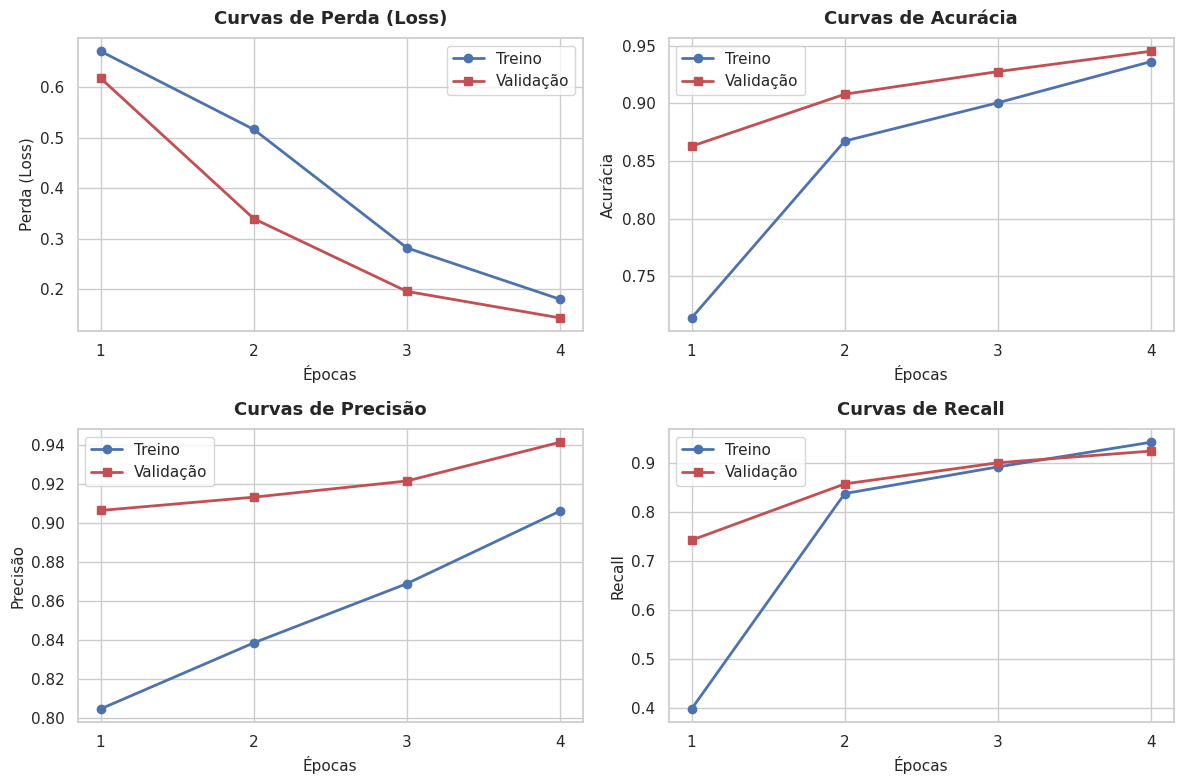

In [ ]:
sb.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Mapea métricas no history
metricas =[
    ('loss', 'Perda (Loss)'),
    ('accuracy', 'Acurácia'),
    ('precision', 'Precisão'),
    ('recall', 'Recall')
]

epocas = range(1, len(history.history['loss']) + 1)

# Renderização do grid
for ax, (metric, nome_exibicao) in zip(axes.flatten(), metricas):
    ax.plot(epocas, history.history[metric], 'b-o', label='Treino', linewidth=2, markersize=6)
    ax.plot(epocas, history.history[f'val_{metric}'], 'r-s', label='Validação', linewidth=2, markersize=6)

    ax.set_title(f'Curvas de {nome_exibicao}', fontsize=13, weight='bold', pad=10)
    ax.set_xlabel('Épocas', fontsize=11)
    ax.set_ylabel(nome_exibicao, fontsize=11)
    ax.set_xticks(epocas)
    ax.legend(loc='best', frameon=True)

plt.tight_layout()
plt.show()

A partir dos resultados acima, observa-se que:

**Perda (Loss)**: Tanto a perda de treino quanto a perda de validação diminuem consistentemente ao longo das épocas. Isso indica que o modelo está aprendendo e se ajustando aos dados. A perda de validação é ligeiramente maior que a perda de treino, o que é esperado e sugere que o modelo não está superajustando (overfitting) significativamente aos dados de treino.

**Acurácia (Accuracy)**: A acurácia do treino e da validação aumenta ao longo das épocas, mostrando que o modelo está melhorando sua capacidade de classificar corretamente as mensagens. As curvas de acurácia de treino e validação estão próximas uma da outra, o que é um bom sinal de generalização.

**Precisão (Precision)**: Ambas as curvas de precisão (treino e validação) aumentam, indicando que a proporção de verdadeiros positivos entre todos os positivos previstos está melhorando.

**Recall**: As curvas de recall também mostram uma tendência de aumento, tanto para o treino quanto para a validação. Isso significa que a capacidade do modelo de identificar corretamente todas as instâncias positivas reais está melhorando.

No geral, os gráficos indicam um bom desempenho do modelo. As curvas de treino e validação seguem tendências semelhantes para todas as métricas, sem grandes divergências, o que sugere que o modelo está aprendendo de forma estável e generalizando bem para dados não vistos. O treinamento por 4 épocas parece ter sido suficiente para o modelo convergir para um bom estado.

#  Avaliação no Conjunto de Teste

In [ ]:
y_teste_prob = modelo.predict(teste_ds).ravel()
y_teste_pred = (y_teste_prob >= limiar_otimo).astype(int)

print("\n[Relatório de Classificação]")
print(classification_report(y_test, y_teste_pred, target_names=['Legitimate', 'Smishing']))


8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step

[Relatório de Classificação]
              precision    recall  f1-score   support

  Legitimate       0.97      0.94      0.96       302
    Smishing       0.92      0.96      0.94       208

    accuracy                           0.95       510
   macro avg       0.95      0.95      0.95       510
weighted avg       0.95      0.95      0.95       510



- ### Matriz de Confusão

In [ ]:
print("[Matriz de Confusão]")
matriz = confusion_matrix(y_test, y_teste_pred)
print(f"Verdadeiros Negativos (Legítimas corretas): {matriz[0, 0]}")
print(f"Falsos Positivos (Legítimas gravadas como Smishing): {matriz[0, 1]}")
print(f"Falsos Negativos (Smishing não detectado): {matriz[1, 0]}")
print(f"Verdadeiros Positivos (Smishing detectado): {matriz[1, 1]}")

[Matriz de Confusão]
Verdadeiros Negativos (Legítimas corretas): 285
Falsos Positivos (Legítimas gravadas como Smishing): 17
Falsos Negativos (Smishing não detectado): 8
Verdadeiros Positivos (Smishing detectado): 200


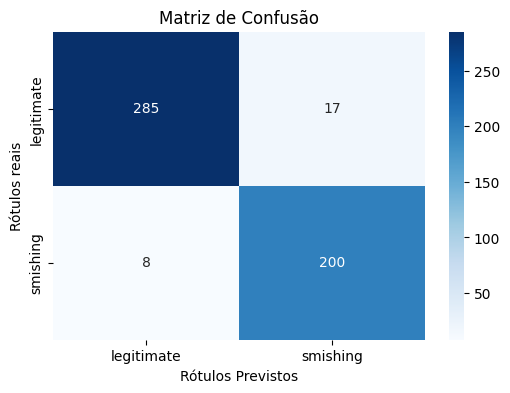

In [ ]:
plt.figure(figsize=(6, 4))
sb.heatmap(matriz, annot=True, fmt='d', cmap='Blues', xticklabels=['legitimate', 'smishing'], yticklabels=['legitimate', 'smishing'])
plt.xlabel('Rótulos Previstos')
plt.ylabel('Rótulos reais')
plt.title('Matriz de Confusão')
plt.show()

# Salvando e exportando o modelo para inferência
---

## Teste de Inferência

In [ ]:
# Mensagens de teste para inferência
mensagens_teste = [
    "Parabéns! Você ganhou um prêmio de R$ 500. Clique no link para resgatar agora: http://banco-fraude.com/resgate",
    "Oi mãe, tudo bem? Consegue me transferir um Pix de 50 reais para pagar a conta de luz? O novo número é este.",
    "Seu código de verificação do WhatsApp é 482-910. Não compartilhe este código com ninguém.",
    "URGENTE: Sua conta bancária será bloqueada devido a transações suspeitas. Regularize agora em: https://seguranca-atualizar.net",
    "Olá! Tudo bem? Passando para lembrar que nossa reunião está confirmada para amanhã às 14h."
]

print("--- Executando Teste de Inferência ---")
print(f"Limiar de decisão utilizado: {limiar_otimo:.4f}\n")

# Previsões
for i, msg in enumerate(mensagens_teste, 1):
    probabilidade = modelo.predict(tf.constant([msg]), verbose=0).ravel()[0]
    classificacao = "Smishing" if probabilidade >= limiar_otimo else "Legitimate"

    print(f"Mensagem {i}: {msg}")
    print(f"Probabilidade: {probabilidade:.4f} -> Classificação: {classificacao}")
    print("-" * 80)

## Extraindo os embiddings do modelo treinado
----

In [ ]:
import numpy as py
import pandas as pd
import tensorflow as tf
import keras
import keras_hub

In [ ]:
# Cria o extrator de features usando a camada densa
extrator_features = tf.keras.Model(
    inputs=modelo.input,
    outputs=modelo.get_layer('pooled_dense').output
)

# Pré-processa o dataset de treino (mapeando a função de pré-processamento do modelo)
treino_ds_preprocessed = treino_ds.map(lambda x, y: (modelo.preprocessor(x), y))

# Extrai a matriz de vetores
embeddings_train = extrator_features.predict(treino_ds_preprocessed)

# Normalização, ajuste dos valores do vetor
embeddings_normalizdos = normalize(embeddings_train, norm="l2")
print(f"Formato da matriz de embeddings: {embeddings_normalizdos.shape}")

### Salvando a matriz e os textos da base original

In [ ]:
df_to_salve = pd.DataFrame({
    "texto": X_train.values,
    "label_original": y_train.values,
    "embedding": list(embeddings_normalizdos)
})

df_to_salve.to_parquet("dataset_avec_embedding.parquet", index=False)
print("DataFrame textos + embeddings salvo com sucesso!")